# 11 - Generative models: an LSTM and a small GPT-like Transformer that write movie reviews
IMDB dataset, text generation (autoregressive language models)

In notebooks 08-10 the networks read a whole review and give one output (non-autoregressive). A
generative model of text learns the distribution of the reviews, so that new reviews can be sampled
from it. An autoregressive language model factorises the probability of a review word by word:

$$P(w_1, \dots, w_T) = \prod_t P(w_t \mid w_1, \dots, w_{t-1}).$$

Each factor is a **classification** problem: given the previous words, predict the next one among the
10,000 words of the vocabulary. The model is trained like a classifier (softmax and cross-entropy) but
with one output at every time step, and the labels come from the text itself (self-supervised). To
generate, we sample one word, append it to the input and repeat.

We train two small models with the same data and the same training loop:

* **LSTM:** 2 layers of 256 units (an RNN generator, as in the class example).
* **Mini-GPT:** a Transformer with 2 layers of masked (causal) self-attention, so that each position can
  only look at the previous words. This is the architecture of LLMs such as GPT, in a tiny version.

The first token of each review is `<pos>` or `<neg>` (its label), so we can ask for a positive or a
negative review (a conditional generative model). A CNN classifier like the one of notebook 08 is then
used as an automatic judge of the sentiment of the generated reviews.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import copy
import time
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.metrics import accuracy_score

from utils import set_style, save, SEED, RES_DIR, PURPLE, PINK, ORANGE, LILAC, PLUM, INK
from imdb_utils import *

set_style()
np.random.seed(SEED)
torch.manual_seed(SEED)
SEQ_LEN = 60          # the first 60 words of each review
LM_VOCAB = 10000

## 1. Data for the language models

In [2]:
d = prepare_imdb(256)
train_df = d["train_df"]
tok_train = [tokenize(t) for t in train_df.text]
idx_tr, idx_val = d["idx_tr"], d["idx_val"]

counts = Counter(t for i in idx_tr for t in tok_train[i])
SPECIAL = ["<pad>", "<unk>", "<pos>", "<neg>"]
itos = SPECIAL + [w for w, _ in counts.most_common(LM_VOCAB - len(SPECIAL))]
stoi = {w: i for i, w in enumerate(itos)}
POS_ID, NEG_ID = stoi["<pos>"], stoi["<neg>"]

def lm_encode(idx):
    X = np.zeros((len(idx), SEQ_LEN + 1), dtype=np.int64)
    for r, i in enumerate(idx):
        first = POS_ID if train_df.label.iloc[i] == 1 else NEG_ID
        ids = [first] + [stoi.get(t, UNK) for t in tok_train[i][:SEQ_LEN]]
        X[r, :len(ids)] = ids
    return torch.tensor(X)

lm_train, lm_val = lm_encode(idx_tr), lm_encode(idx_val)
print("sequences", tuple(lm_train.shape), "| example:", " ".join(itos[i] for i in lm_train[0, :15]))
print(f"unknown words: {(lm_train == UNK).float().mean():.1%}")

sequences (20000, 61) | example: <pos> i have always been a huge james bond fanatic ! i have seen almost
unknown words: 5.0%


The input is the sequence without its last word and the target is the same sequence shifted by one
position, so at every step the target is the next word. The padding is ignored in the loss.

In [3]:
x, y = lm_train[:1, :-1], lm_train[:1, 1:]
print("input :", [itos[i] for i in x[0, :6]])
print("target:", [itos[i] for i in y[0, :6]])

input : ['<pos>', 'i', 'have', 'always', 'been', 'a']
target: ['i', 'have', 'always', 'been', 'a', 'huge']


## 2. The two language models

In both models the last linear layer is applied to the output of every time step (no "time-distributed"
layer is needed in PyTorch, `nn.Linear` works on the last dimension). In the mini-GPT the causal mask
sets the attention to future positions to minus infinity, so their weight after the softmax is 0.

In [4]:
class LSTMLanguageModel(nn.Module):
    def __init__(self, vocab_size, emb_dim=128, hidden=256, n_layers=2, dropout=0.3):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD)
        self.lstm = nn.LSTM(emb_dim, hidden, n_layers, batch_first=True, dropout=dropout)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(hidden, vocab_size)

    def forward(self, x):
        out, _ = self.lstm(self.drop(self.emb(x)))
        return self.fc(self.drop(out))           # (batch, sequence, vocabulary) logits


class MiniGPT(nn.Module):
    def __init__(self, vocab_size, max_len=SEQ_LEN + 1, d_model=128, n_heads=4, n_layers=2, d_ff=512,
                 dropout=0.1):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, d_model, padding_idx=PAD)
        self.pos = nn.Embedding(max_len, d_model)
        layer = nn.TransformerEncoderLayer(d_model, n_heads, d_ff, dropout, batch_first=True)
        self.blocks = nn.TransformerEncoder(layer, n_layers, enable_nested_tensor=False)
        self.fc = nn.Linear(d_model, vocab_size)

    def forward(self, x):
        T = x.size(1)
        causal = nn.Transformer.generate_square_subsequent_mask(T, device=x.device)
        h = self.emb(x) + self.pos(torch.arange(T, device=x.device))
        return self.fc(self.blocks(h, mask=causal, is_causal=True))


print("causal mask for 4 positions:\n", nn.Transformer.generate_square_subsequent_mask(4))

# check: the outputs for the first 10 words must not depend on the words that come later
torch.manual_seed(0)
check = MiniGPT(len(itos)).to(DEVICE).eval()
with torch.no_grad():
    xb = lm_train[:8, :-1].to(DEVICE)
    print("max difference using only the first 10 words:", (check(xb)[:, :10] - check(xb[:, :10])).abs().max().item())
del check

causal mask for 4 positions:
 tensor([[0., -inf, -inf, -inf],
        [0., 0., -inf, -inf],
        [0., 0., 0., -inf],
        [0., 0., 0., 0.]])


max difference using only the first 10 words: 1.0728836059570312e-06


In [5]:
ce = nn.CrossEntropyLoss(ignore_index=PAD)    # includes the softmax

def lm_loss(model, X, batch_size=256):
    model.eval()
    total, count = 0.0, 0
    with torch.no_grad():
        for i in range(0, len(X), batch_size):
            xb = X[i:i + batch_size].to(DEVICE)
            logits = model(xb[:, :-1])
            n = (xb[:, 1:] != PAD).sum().item()
            total += ce(logits.reshape(-1, logits.size(-1)), xb[:, 1:].reshape(-1)).item() * n
            count += n
    return total / count

def train_lm(model, lr, max_epochs=8, patience=2, batch_size=64):
    torch.manual_seed(SEED)
    model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    g = torch.Generator().manual_seed(SEED)
    history, best, best_state, wait = [], np.inf, None, 0
    for epoch in range(max_epochs):
        model.train()
        start, running, count = time.time(), 0.0, 0
        for b in torch.randperm(len(lm_train), generator=g).split(batch_size):
            xb = lm_train[b].to(DEVICE)
            opt.zero_grad()
            logits = model(xb[:, :-1])
            loss = ce(logits.reshape(-1, logits.size(-1)), xb[:, 1:].reshape(-1))
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
            running, count = running + loss.item(), count + 1
        val = lm_loss(model, lm_val)
        history.append({"epoch": epoch + 1, "train loss": running / count, "val loss": val,
                        "val perplexity": np.exp(val), "seconds": time.time() - start})
        print(f"  epoch {epoch + 1}: train {running / count:.3f}, val {val:.3f} "
              f"(perplexity {np.exp(val):.0f}), {time.time() - start:.0f} s")
        if val < best - 1e-3:
            best, best_state, wait = val, copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= patience:
                break
    model.load_state_dict(best_state)
    return pd.DataFrame(history)

models, histories = {}, {}
for name, build, lr in [("LSTM", lambda: LSTMLanguageModel(len(itos)), 2e-3),
                        ("Mini-GPT", lambda: MiniGPT(len(itos)), 1e-3)]:
    torch.manual_seed(SEED)
    models[name] = build()
    print(f"{name}: {count_parameters(models[name]):,} parameters")
    histories[name] = train_lm(models[name], lr)
pd.concat(histories, names=["model"]).to_csv(RES_DIR / "imdb_lm_history.csv")
lm_summary = pd.DataFrame({name: {"parameters": count_parameters(m),
                                  "best val perplexity": h["val perplexity"].min(),
                                  "epochs": len(h), "seconds per epoch": h["seconds"].mean()}
                           for (name, m), h in zip(models.items(), histories.values())}).T
print(f"(a uniform guess would have a perplexity of {len(itos):,})")
lm_summary.round(1)

LSTM: 4,771,600 parameters


  epoch 1: train 6.606, val 6.479 (perplexity 651), 46 s


  epoch 2: train 6.323, val 6.285 (perplexity 536), 53 s


  epoch 3: train 6.075, val 6.058 (perplexity 427), 66 s


  epoch 4: train 5.926, val 5.920 (perplexity 373), 62 s


  epoch 5: train 5.815, val 5.732 (perplexity 309), 67 s


... (10 outputs left out)

  epoch 7: train 4.841, val 5.110 (perplexity 166), 57 s


  epoch 8: train 4.771, val 5.106 (perplexity 165), 66 s


(a uniform guess would have a perplexity of 10,000)


,parameters,best val perplexity,epochs,seconds per epoch
LSTM,4771600.0,221.2,8.0,62.3
Mini-GPT,2974352.0,165.0,8.0,58.2


## 3. Generating = classifying the next word, many times

After `<pos> this movie is` the output of the network is a probability distribution over the
10,000 words. Changing only the first token changes the distribution.

In [6]:
@torch.no_grad()
def next_word_probs(model, words):
    model.eval()
    x = torch.tensor([[stoi.get(w, UNK) for w in words]], device=DEVICE)
    return torch.softmax(model(x)[0, -1], dim=0).cpu().numpy()

prompt = ["this", "movie", "is"]
next_pos = next_word_probs(models["LSTM"], ["<pos>"] + prompt)
next_neg = next_word_probs(models["LSTM"], ["<neg>"] + prompt)
top_words = list(dict.fromkeys([itos[i] for i in np.argsort(-next_pos)[:8]] +
                               [itos[i] for i in np.argsort(-next_neg)[:8]]))
next_table = pd.DataFrame({"<pos>": [next_pos[stoi[w]] for w in top_words],
                           "<neg>": [next_neg[stoi[w]] for w in top_words]}, index=top_words)
next_table.round(3)

,<pos>,<neg>
a,0.122,0.096
not,0.052,0.051
the,0.052,0.043
one,0.031,0.023
very,0.026,0.021
so,0.023,0.027
<unk>,0.021,0.021
an,0.019,0.015
just,0.019,0.021


In [7]:
@torch.no_grad()
def generate(model, sentiment, n_words=40, temperature=1.0, n=1, seed=SEED):
    """Autoregressive sampling: the sampled word becomes part of the input of the next step."""
    model.eval()
    gen = torch.Generator().manual_seed(seed)
    x = torch.full((n, 1), POS_ID if sentiment == "pos" else NEG_ID, device=DEVICE)
    for _ in range(n_words):
        logits = model(x)[:, -1] / temperature
        logits[:, [PAD, UNK, POS_ID, NEG_ID]] = -np.inf     # never generate the special tokens
        nxt = torch.multinomial(torch.softmax(logits, dim=1).cpu(), 1, generator=gen)
        x = torch.cat([x, nxt.to(DEVICE)], dim=1)
    return [[itos[i] for i in row[1:]] for row in x.cpu().numpy()]

examples = []
for name, model in models.items():
    for sentiment in ["pos", "neg"]:
        for temp in [0.5, 1.0, 1.5]:
            text = " ".join(generate(model, sentiment, 30, temp, seed=SEED)[0])
            examples.append({"model": name, "sentiment": sentiment, "temperature": temp, "text": text})
            print(f"{name} <{sentiment}> T={temp}: {text}\n")
pd.DataFrame(examples).to_csv(RES_DIR / "imdb_generated_examples.csv", index=False)

LSTM <pos> T=0.5: i have to be a hard film with a great movie i was very disappointed that i was found to see it i was a good movie the acting was

LSTM <pos> T=1.0: birth ! sunshine and the many performance with love ground my other sexual black book still filled by the colorful show is being its videos it suffers the actual impression



LSTM <pos> T=1.5: birth ! sunshine lends carson many criminals ambition love ground my thing differently brenda book cathy filled explains terms how dies george errol radiation videos provides hurt word actual impression

LSTM <neg> T=0.5: i have to be a hard film with a movie that i was very disappointed that i was disappointed to get it for a lot of a word i was



LSTM <neg> T=1.0: first ! my name who did it will love me my thing the british book is filled by the rest of us being its videos it suffers word around an

LSTM <neg> T=1.5: birth ! sunshine lends carson many hoping rather love ground my thing differently tom book cathy filled explains terms how dies george errol radiation videos freaking hurt word actual impression



Mini-GPT <pos> T=0.5: i saw this film on the map i love the cinema i was very disappointed that the movie was very good and the acting was great ! the acting was

Mini-GPT <pos> T=1.0: three musicals sunshine and animation to be rather watchable in my opinion the short book that virtually users of how promises us westerns was videos to hurt the actual girl



Mini-GPT <pos> T=1.5: birth musicals sunshine rambo carson many talented ambition love carnage my eyes is tom carey cathy virtually must've dealt with his name errol radiation videos freaking hurt word actual girl

Mini-GPT <neg> T=0.5: i can't believe i watched this film with my friend and i was watching it i was so disappointed i was not expecting a good movie with the actual jokes



Mini-GPT <neg> T=1.0: first of all i watched many times with love zombies my expectations i am glad that bad movies strongly sadly however i got its videos freaking down the actual impression

Mini-GPT <neg> T=1.5: birth directors without rambo carson many staple ambition love ground my eyes differently brenda carey cathy virtually must've found how promises us errol radiation videos freaking ! word actual girl



## 4. Do the generated reviews have the requested sentiment?

We train the CNN of notebook 08 (same data, seed 42) and use it as an automatic judge: for each model
and temperature we generate 200 positive and 200 negative reviews of 40 words and count how many are
classified with the requested sentiment. The diversity is the fraction of distinct word pairs
(bigrams) among all the generated pairs. As a reference, the same measures are computed on the first
40 words of 400 real validation reviews.

In [8]:
torch.manual_seed(SEED)
judge = TextCNN(d["vocab_size"])
train_text_model(judge, d["train"], d["val"], seed=SEED)
print("judge accuracy on the test reviews:",
      round(accuracy_score(d["test"][2], predict_proba(judge, *d["test"][:2]) > 0.5), 4))

def judge_positive(reviews):
    X, L = encode(reviews, d["vocab"], 256)
    return predict_proba(judge, X, L)

def distinct_bigrams(reviews):
    pairs = [(a, b) for r in reviews for a, b in zip(r[:-1], r[1:])]
    return len(set(pairs)) / len(pairs)

real = [tok_train[i][:40] for i in idx_val[:400]]
real_labels = train_df.label.values[idx_val[:400]]
rows = [{"model": "real reviews", "temperature": np.nan,
         "sentiment agreement": accuracy_score(real_labels, judge_positive(real) > 0.5),
         "distinct bigrams": distinct_bigrams(real)}]
for name, model in models.items():
    for temp in [0.5, 0.8, 1.0, 1.2, 1.5]:
        pos = generate(model, "pos", 40, temp, n=200, seed=1)
        neg = generate(model, "neg", 40, temp, n=200, seed=2)
        p = judge_positive(pos + neg)
        agree = np.mean(np.concatenate([p[:200] > 0.5, p[200:] < 0.5]))
        rows.append({"model": name, "temperature": temp, "sentiment agreement": agree,
                     "distinct bigrams": distinct_bigrams(pos + neg)})
        print(f"{name:8s} T = {temp}: sentiment agreement {agree:.3f}, distinct bigrams {rows[-1]['distinct bigrams']:.3f}")
gen_eval = pd.DataFrame(rows)
gen_eval.to_csv(RES_DIR / "imdb_generation_eval.csv", index=False)
gen_eval.round(3)

judge accuracy on the test reviews: 0.8664


LSTM     T = 0.5: sentiment agreement 0.825, distinct bigrams 0.138


LSTM     T = 0.8: sentiment agreement 0.725, distinct bigrams 0.495


LSTM     T = 1.0: sentiment agreement 0.652, distinct bigrams 0.761


LSTM     T = 1.2: sentiment agreement 0.600, distinct bigrams 0.915


LSTM     T = 1.5: sentiment agreement 0.585, distinct bigrams 0.986


... (2 outputs left out)

Mini-GPT T = 1.0: sentiment agreement 0.738, distinct bigrams 0.690


Mini-GPT T = 1.2: sentiment agreement 0.677, distinct bigrams 0.864


Mini-GPT T = 1.5: sentiment agreement 0.605, distinct bigrams 0.969


,model,temperature,sentiment agreement,distinct bigrams
0,real reviews,NaN,0.740,0.732
1,LSTM,0.5,0.825,0.138
2,LSTM,0.8,0.725,0.495
3,LSTM,1.0,0.652,0.761
4,LSTM,1.2,0.600,0.915
5,LSTM,1.5,0.585,0.986
6,Mini-GPT,0.5,0.888,0.164
7,Mini-GPT,0.8,0.800,0.447
8,Mini-GPT,1.0,0.738,0.690
9,Mini-GPT,1.2,0.678,0.864


Figure saved -> ../results/figures/imdb_generation.png


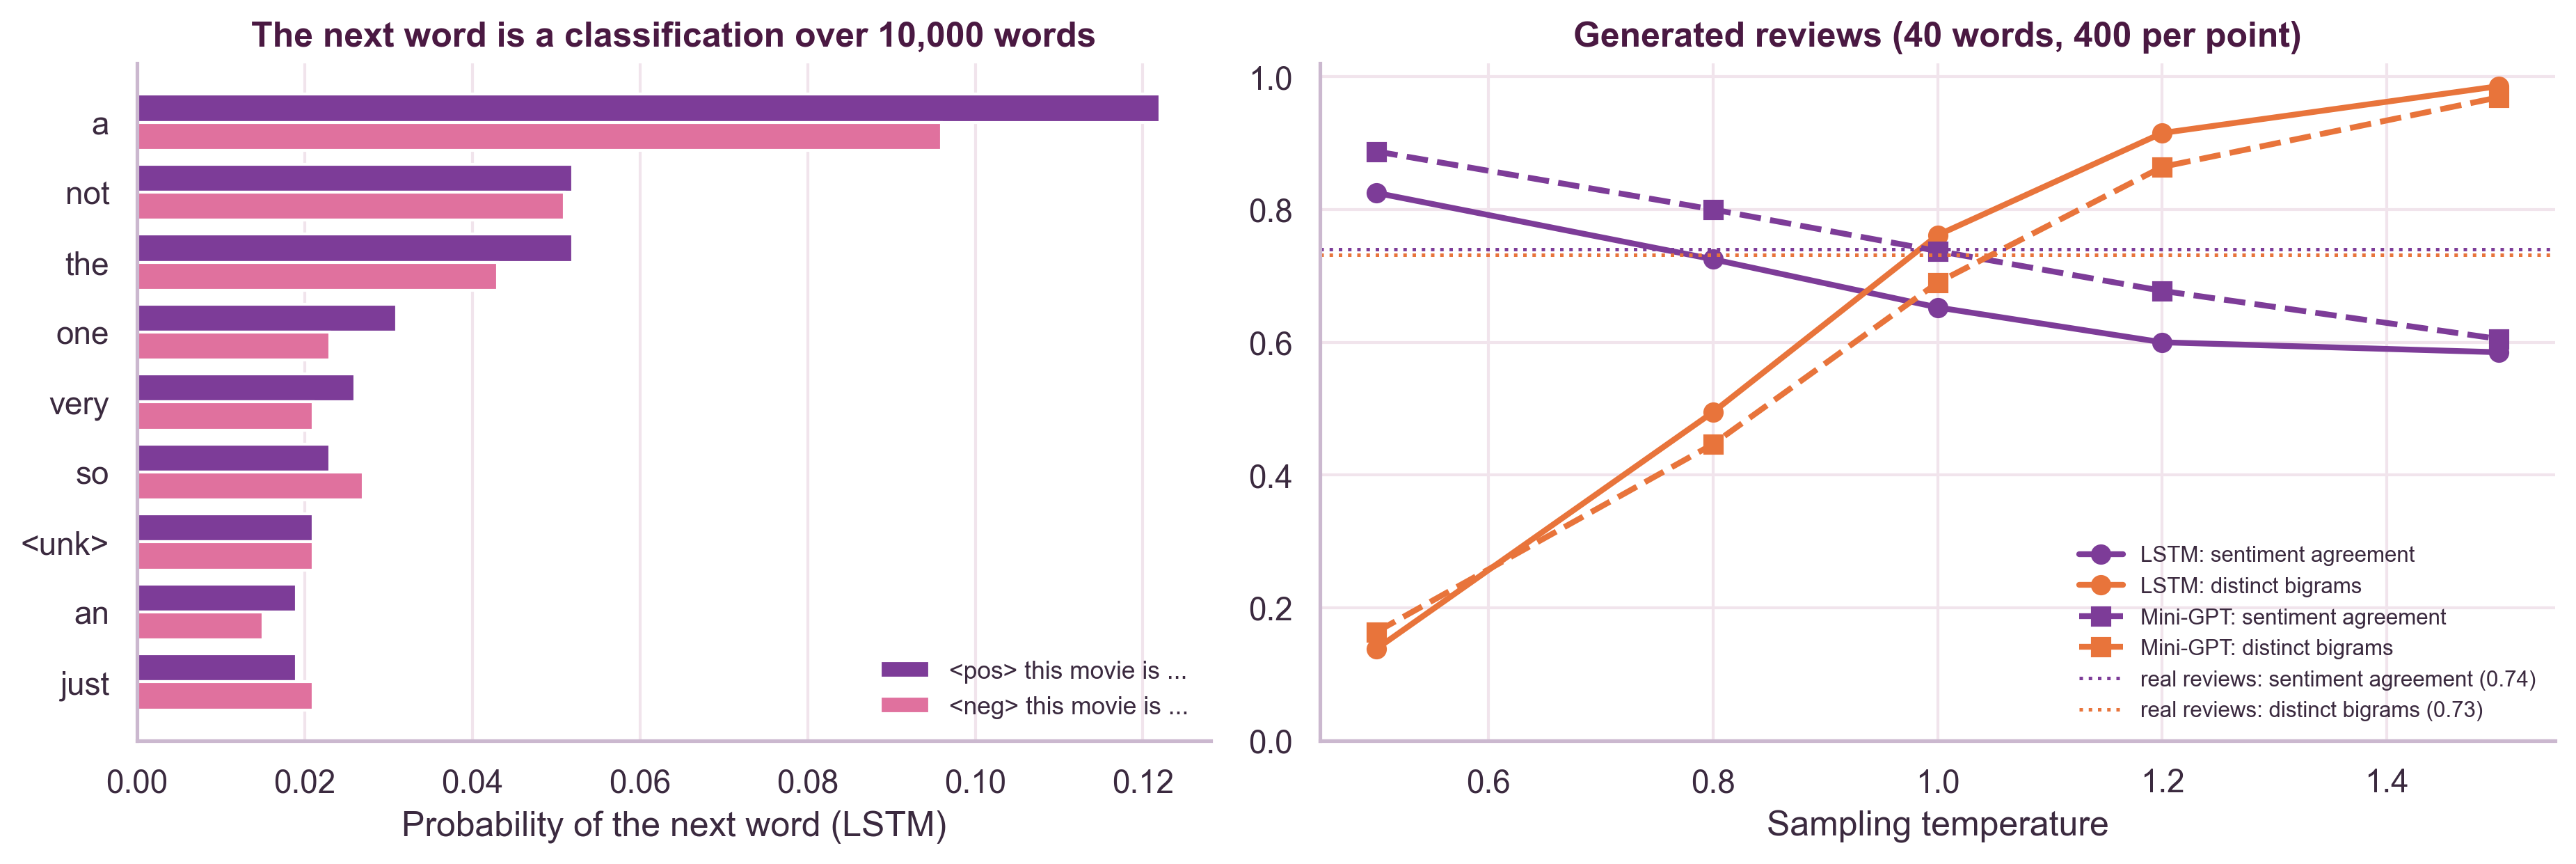

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3), gridspec_kw=dict(width_ratios=[1, 1.15]))
ax = axes[0]
yy = np.arange(len(next_table))
ax.barh(yy - 0.2, next_table["<pos>"], 0.4, color=PURPLE, label="<pos> this movie is ...")
ax.barh(yy + 0.2, next_table["<neg>"], 0.4, color=PINK, label="<neg> this movie is ...")
ax.set_yticks(yy, next_table.index)
ax.invert_yaxis()
ax.set_xlabel("Probability of the next word (LSTM)")
ax.set_title("The next word is a classification over 10,000 words")
ax.legend(fontsize=8.5, loc="lower right")
ax.grid(axis="y", visible=False)
ax = axes[1]
for name, ls, mk in [("LSTM", "-", "o"), ("Mini-GPT", "--", "s")]:
    ge = gen_eval[gen_eval.model == name]
    ax.plot(ge.temperature, ge["sentiment agreement"], ls=ls, marker=mk, lw=2, color=PURPLE,
            label=f"{name}: sentiment agreement")
    ax.plot(ge.temperature, ge["distinct bigrams"], ls=ls, marker=mk, lw=2, color=ORANGE,
            label=f"{name}: distinct bigrams")
real_row = gen_eval.iloc[0]
ax.axhline(real_row["sentiment agreement"], color=PURPLE, ls=":", lw=1.2,
           label=f"real reviews: sentiment agreement ({real_row['sentiment agreement']:.2f})")
ax.axhline(real_row["distinct bigrams"], color=ORANGE, ls=":", lw=1.2,
           label=f"real reviews: distinct bigrams ({real_row['distinct bigrams']:.2f})")
ax.set_xlabel("Sampling temperature")
ax.set_ylim(0, 1.02)
ax.set_title("Generated reviews (40 words, 400 per point)")
ax.legend(fontsize=7.5, loc="lower right")
fig.tight_layout()
save(fig, "imdb_generation.png")
plt.show()

## Summary

- **Language modelling.** The Mini-GPT (3.0 M parameters) learns the language better than the LSTM (4.8 M): best validation perplexity 165 vs 221 (uniform guess: 10,000), with the same time per epoch. Neither model has fully converged after 8 epochs.
- **Generating = classifying the next word.** After `<pos> this movie is` the most probable words are *a*, *not* and *the*, and changing the first token to `<neg>` only changes these probabilities slightly.
- **Temperature.** With T = 0.5 the reviews have the requested sentiment (agreement 0.83 LSTM, 0.89 Mini-GPT) but are very repetitive (14-16% distinct bigrams) and not coherent over a whole sentence. With higher temperatures the diversity increases and the agreement decreases; at T = 1.5 the texts are almost random words. Around T = 1 the diversity is similar to real reviews (0.69-0.76 vs 0.73).
- The Mini-GPT has a higher sentiment agreement than the LSTM at every temperature.
- The agreement at low temperature is higher than for real reviews (0.74) because the generated texts use the most typical words of each class, while real reviews often start by describing the plot.
- **Decoding strategies.** The course theory also covers greedy decoding ($\tau \to 0$) and top-$k$ sampling. This notebook only sweeps temperature; greedy and top-$k$ are neighbouring strategies of the same idea, and low temperature already behaves close to greedy. The trained generators were not saved as checkpoints, so a separate side-by-side of the three methods was not added without retraining.